# Prediccion de recompra: `Output`

El objetivo es clasificar si un cliente volvera a ordenar (`Yes` o `No`). El CSV tiene 388 filas; tras limpiar texto y quitar 103 filas repetidas quedan 285 registros unicos. La clase `Yes` representa el 76.1% y `No` el 23.9%, por lo que accuracy no basta para evaluar el modelo.

Compararemos un baseline, regresion logistica y random forest con train y validacion, y reservaremos un conjunto de test para evaluar una sola vez el modelo elegido. Excluimos `Feedback` porque podria registrarse despues del pedido y filtrar informacion futura. Al final se incluye importancia de variables y material para interpretar los resultados en la presentacion.

## 1. Importaciones y carga

La busqueda del archivo funciona tanto si Jupyter inicia en la carpeta del proyecto como si inicia en `notebooks/`.

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

file_name = "online food delivery dataset.csv"
data_candidates = [
    Path.cwd() / "data" / file_name,
    Path.cwd().parent / "data" / file_name,
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        f"No se encontro {file_name}. Directorio actual: {Path.cwd()}"
    )

df = pd.read_csv(data_path)
raw_rows = len(df)
text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

target = "Output"
if target not in df.columns:
    raise KeyError(f"No se encontro la columna objetivo {target!r}")

unnamed_columns = [
    column for column in df.columns
    if str(column).strip().lower().startswith("unnamed")
]
for column in unnamed_columns:
    if not df[column].equals(df[target]):
        raise ValueError(
            f"La columna sin nombre {column!r} no es una copia exacta de {target!r}"
        )
    df = df.drop(columns=column)

duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
if df[target].isna().any() or set(df[target].unique()) != {"Yes", "No"}:
    raise ValueError("Output debe contener unicamente las clases 'Yes' y 'No', sin faltantes.")

print(f"Archivo: {data_path}")
print(f"Filas originales: {raw_rows}")
print(f"Filas duplicadas eliminadas: {duplicate_rows}")
print(f"Filas unicas para el analisis: {len(df)}")
print("Distribucion del objetivo:")
display(df[target].value_counts().rename_axis("Output").to_frame("clientes"))
display(df.head())

Archivo: c:\Users\regih\OneDrive\Documentos\AI_DA_Chein\data\online food delivery dataset.csv
Filas originales: 388
Filas duplicadas eliminadas: 103
Filas unicas para el analisis: 285
Distribucion del objetivo:


,clientes
Output,
Yes,217
No,68


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive


## 2. Limpieza y prevencion de fuga de informacion

El CSV incluye una columna final sin nombre que parece duplicar `Output`. La verificamos antes de quitarla para no descartar silenciosamente una columna inesperada. Tambien quitamos filas repetidas antes de separar entrenamiento y prueba: de otro modo, copias de una misma observacion podrian caer en ambos conjuntos.

In [10]:
excluded_columns = [target, "Feedback", "Customer Type", "Pin code"]
missing_exclusions = [column for column in excluded_columns if column not in df.columns]
if missing_exclusions:
    raise KeyError(f"Faltan columnas esperadas: {missing_exclusions}")

# Feedback podria registrarse despues del pedido; Customer Type replica Family size.
X = df.drop(columns=excluded_columns)
y = df[target]

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val,
)

split_summary = pd.DataFrame(
    {
        "Registros": [len(X_train), len(X_val), len(X_test)],
        "No": [(y_train == "No").sum(), (y_val == "No").sum(), (y_test == "No").sum()],
        "Yes": [(y_train == "Yes").sum(), (y_val == "Yes").sum(), (y_test == "Yes").sum()],
    },
    index=["Entrenamiento", "Validacion", "Test final"],
)
print("Variables predictoras:", X.columns.tolist())
display(split_summary)

Variables predictoras: ['Age', 'Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Family size', 'latitude', 'longitude']


,Registros,No,Yes
Entrenamiento,171,40,131
Validacion,57,14,43
Test final,57,14,43


## 3. Variables predictoras y particiones

El objetivo `y` es `Output` (`Yes` = volvio a ordenar, `No` = no volvio). Es un problema de clasificacion binaria. Excluimos `Feedback` porque podria conocerse despues del pedido, `Customer Type` porque coincide con `Family size` en estos datos, y `Pin code` por ser un identificador geografico. El resto de las variables se usa como `X`.

Separamos los datos unicos en entrenamiento (60%), validacion (20%) y test final (20%), manteniendo la proporcion de las clases. El test queda reservado hasta seleccionar un modelo con validacion.

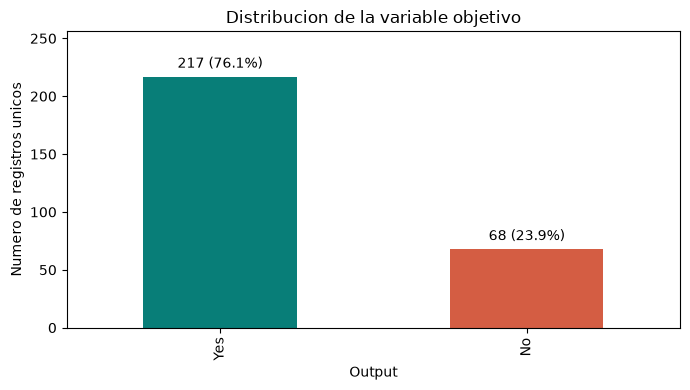

In [11]:
target_counts = df[target].value_counts().reindex(["Yes", "No"])
target_percentages = target_counts / target_counts.sum() * 100

ax = target_counts.plot(
    kind="bar",
    figsize=(7, 4),
    color=["#087E78", "#D45D43"],
)
for bar, count, percentage in zip(ax.patches, target_counts, target_percentages):
    ax.annotate(
        f"{count} ({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
    )
ax.set_title("Distribucion de la variable objetivo")
ax.set_xlabel("Output")
ax.set_ylabel("Numero de registros unicos")
ax.set_ylim(0, target_counts.max() * 1.18)
plt.tight_layout()
plt.show()

## 4. Entrenamiento y seleccion con validacion

Comparamos un baseline de clase frecuente con regresion logistica y random forest. Las variables categoricas se codifican con one-hot encoding y las numericas se escalan dentro de un pipeline, ajustado solo con entrenamiento. La clase `No` tiene menos ejemplos; por eso comparamos accuracy junto con balanced accuracy y F1 para `No`. El modelo se elige con F1 de validacion para `No` (desempate: balanced accuracy), no con el test.

In [ ]:
categorical_columns = X_train_val.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()
numeric_columns = [column for column in X_train_val.columns if column not in categorical_columns]
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numeric", StandardScaler(), numeric_columns),
    ]
)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

baseline = Pipeline([("classifier", DummyClassifier(strategy="most_frequent"))])
logistic = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=42)),
])
rf = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=400, class_weight="balanced", random_state=42, n_jobs=-1
    )),
])
svc = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(class_weight="balanced", probability=True, random_state=42)),
])

searches = {
    "Baseline (clase frecuente)": (baseline, {}),
    "Regresion logistica": (logistic, {
        "classifier__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
        "classifier__penalty": ["l1", "l2"],
        "classifier__solver": ["liblinear"],
    }),
    "Random forest": (rf, {
        "classifier__max_depth": [None, 4, 6, 8],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__max_features": ["sqrt", 0.5],
    }),
    "SVM RBF": (svc, {
        "classifier__C": [0.1, 0.3, 1.0, 3.0, 10.0],
        "classifier__gamma": ["scale", "auto", 0.01, 0.03, 0.1],
    }),
}

cv_rows = []
fitted_models = {}
for model_name, (model, parameters) in searches.items():
    if parameters:
        search = GridSearchCV(
            model,
            parameters,
            scoring="balanced_accuracy",
            cv=cv,
            n_jobs=-1,
            return_train_score=False,
        )
        search.fit(X_train_val, y_train_val)
        fitted = search.best_estimator_
        best_cv = search.best_score_
        best_params = search.best_params_
    else:
        fitted = model.fit(X_train_val, y_train_val)
        cv_scores = cross_val_score(
            fitted, X_train_val, y_train_val,
            scoring="balanced_accuracy", cv=cv, n_jobs=-1,
        )
        best_cv = cv_scores.mean()
        best_params = {}

    fitted_models[model_name] = fitted
    predictions_val = fitted.predict(X_val)
    cv_rows.append({
        "Modelo": model_name,
        "CV balanced accuracy": best_cv,
        "Validacion balanced accuracy": balanced_accuracy_score(y_val, predictions_val),
        "Validacion F1 No": f1_score(y_val, predictions_val, pos_label="No", zero_division=0),
        "Parametros": best_params,
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ["Validacion balanced accuracy", "Validacion F1 No"], ascending=False
)
display(cv_results.round(3))


### Comparacion visual y eleccion del modelo

Las graficas comparan train con validacion. Una diferencia grande puede indicar sobreajuste. Elegimos por balanced accuracy de validacion, que considera ambas clases; usamos F1 de `No` para desempatar. El test no participa en esta decision.

In [ ]:
# Elige el mejor modelo por la exactitud balanceada obtenida en validacion.
best_model_name = cv_results.sort_values(
    ["Validacion balanced accuracy", "Validacion F1 No"], ascending=False
).iloc[0]["Modelo"]
selected_model = fitted_models[best_model_name]

test_predictions = selected_model.predict(X_test)
test_yes_probability = selected_model.predict_proba(X_test)[:, list(selected_model.classes_).index("Yes")]

print("Modelo seleccionado:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 3))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, test_predictions), 3))
print("F1 clase No:", round(f1_score(y_test, test_predictions, pos_label="No", zero_division=0), 3))
print("ROC-AUC clase Yes:", round(roc_auc_score(y_test == "Yes", test_yes_probability), 3))

matrix = confusion_matrix(y_test, test_predictions, labels=["No", "Yes"])
display(pd.DataFrame(
    matrix,
    index=pd.Index(["Real No", "Real Yes"], name="Real"),
    columns=pd.Index(["Predicho No", "Predicho Yes"], name="Prediccion"),
))
print(classification_report(y_test, test_predictions, labels=["No", "Yes"], zero_division=0))


In [ ]:
importancia = permutation_importance(
    selected_model,
    X_val,
    y_val,
    scoring="balanced_accuracy",
    n_repeats=30,
    random_state=42,
)

if "categorical_columns" not in globals():
    categorical_columns = X_val.select_dtypes(include=["object", "category", "string"]).columns.tolist()

importance_df = pd.DataFrame({
    "Variable": X_val.columns,
    "Importancia media": importancia.importances_mean,
    "Desviacion": importancia.importances_std,
}).sort_values("Importancia media", ascending=True)

display(importance_df.sort_values("Importancia media", ascending=False).round(4))


In [ ]:
from sklearn.base import clone

# Reentrenar el modelo seleccionado con train+validacion y evaluarlo una vez en test.
final_model = clone(selected_model)
final_model.fit(X_train_val, y_train_val)
test_predictions = final_model.predict(X_test)
test_yes_probability = final_model.predict_proba(X_test)[:, list(final_model.classes_).index("Yes")]
test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Balanced accuracy": balanced_accuracy_score(y_test, test_predictions),
    "F1 clase No": f1_score(y_test, test_predictions, pos_label="No", zero_division=0),
    "ROC-AUC (Yes)": roc_auc_score(y_test == "Yes", test_yes_probability),
}

print(f"Modelo final: {best_model_name}")
print("Metricas del test final (57 registros; 14 son clase No):")
display(pd.Series(test_metrics, name="Puntaje").to_frame().round(3))


## 6. Conclusiones

- El modelo se selecciona con validacion cruzada estratificada repetida y se evalua una sola vez en test.
- No se usa `Feedback`, `Customer Type`, ni `Pin code`, lo que reduce el riesgo de fuga y elimina variables redundantes o identificadores.
- Accuracy puede seguir dominado por `Yes`; balanced accuracy, F1 de `No` y ROC-AUC son las medidas principales.
- La prueba final valida la generalizacion, pero con solo 57 registros el intervalo real de incertidumbre puede ser amplio.
